# Clasificación Multiclase de Razas de Perro mediante Red Convolucional (CNN)

## a. Introducción
El presente proyecto aborda un problema de visión artificial de grano fino (*fine-grained classification*): identificar la **raza** de un animal a partir de su imagen, utilizando el **Oxford-IIIT Pet Dataset**. Este conjunto de datos recopila imágenes reales "in the wild" que presentan variaciones importantes de iluminación, escala, posturas y fondos complejos.

**Variante definida para el proyecto:** A diferencia del enfoque original del dataset (37 clases: 25 razas de perro y 12 de gato), esta variante se limita estrictamente a una sola especie, el **perro (`Dog`)**, de modo que el problema queda restringido a una **clasificación multiclase de 25 clases**. Las imágenes de gatos se descartan durante la preparación del dataset.

**Arquitectura propuesta:** En lugar del Perceptrón Multicapa (MLP) que aplana la imagen y pierde toda la información espacial, este informe utiliza una **Red Neuronal Convolucional (CNN) básica**. Las convoluciones permiten detectar patrones locales reutilizables (textura del pelaje, contorno del hocico, forma de las orejas) en cualquier posición de la imagen, lo que resulta decisivo en un problema donde las pistas discriminativas entre razas son pequeñas y sutiles.

**Objetivo del modelo:** Diseñar, entrenar y evaluar una CNN capaz de distinguir con la mayor precisión posible la raza del perro, reduciendo la confusión entre las clases visualmente más parecidas (e.g. `american_bulldog` vs. `staffordshire_bull_terrier`).

**Justificación de la elección del dataset:** Se selecciona el Oxford-IIIT Pet Dataset por su robustez estándar en la investigación académica y porque sus condiciones reales de captura permiten evaluar de manera empírica las capacidades de aprendizaje de una red convolucional propia frente a un problema de 25 clases, sin recurrir a modelos preentrenados.

## b. Comprensión y exploración del conjunto de datos
El conjunto de datos original contiene 7.390 imágenes de mascotas con anotaciones de la especie y la raza embebidas en el nombre del archivo (por ejemplo, `beagle_115.jpg` o `Siamese_133.jpg`). La regla de nombrado del dataset permite recuperar ambas etiquetas de forma analítica: los nombres que comienzan con mayúscula corresponden a **gatos** (`Cat`) y los que comienzan en minúscula a **perros** (`Dog`).

En esta variante se aplica un **filtrado por especie** que conserva únicamente las 4.990 imágenes de perros, distribuidas en **25 razas**. Cada clase es una categoría semántica (*fine-grained*) y no una categoría visual básica, por lo que las diferencias entre clases son sutiles.

**Características y dificultades esperadas:**
1. **Grano fino (25 clases):** Las razas comparten estructura corporal, pelaje y escenarios; las pistas discriminativas son sutiles (proporción del hocico, forma de orejas, textura del pelaje).
2. **Confusión entre pares similares:** Razas como `beagle` / `english_cocker_spaniel` o `pomeranian` / `japanese_chin` comparten rasgos que un modelo puramente denso no logra capturar, y que exigen una arquitectura capaz de analizar regiones locales de la imagen.
3. **Ruido ambiental:** Fondos complejos, presencia de humanos y oclusiones visuales que perturban la señal de la raza.
4. **Variabilidad intra-clase:** Diferencias masivas de tamaños, poses y colores de pelaje dentro de una misma raza.
5. **Distribución aproximadamente balanceada:** A diferencia de la clasificación binaria del enunciado original (2:1 perro/gato), la subdivisión por perro distribuye las imágenes de forma mucho más homogénea entre las 25 clases, reduciendo el riesgo de colapso hacia una clase mayoritaria.

Using Colab cache for faster access to the 'the-oxfordiiit-pet-dataset' dataset.
Dataset descargado en ruta: /kaggle/input/the-oxfordiiit-pet-dataset
Total de imágenes en el dataset: 7390

Distribución original por especie:
 species
Dog    4990
Cat    2400
Name: count, dtype: int64

Total de imágenes de perros: 4990
Número de clases (razas de perro): 25

Mapa índice -> raza:
   0 -> american_bulldog
   1 -> american_pit_bull_terrier
   2 -> basset_hound
   3 -> beagle
   4 -> boxer
   5 -> chihuahua
   6 -> english_cocker_spaniel
   7 -> english_setter
   8 -> german_shorthaired
   9 -> great_pyrenees
  10 -> havanese
  11 -> japanese_chin
  12 -> keeshond
  13 -> leonberger
  14 -> miniature_pinscher
  15 -> newfoundland
  16 -> pomeranian
  17 -> pug
  18 -> saint_bernard
  19 -> samoyed
  20 -> scottish_terrier
  21 -> shiba_inu
  22 -> staffordshire_bull_terrier
  23 -> wheaten_terrier
  24 -> yorkshire_terrier

Entrenamiento: 3493 imágenes
Validación:    748 imágenes
Prueba:      

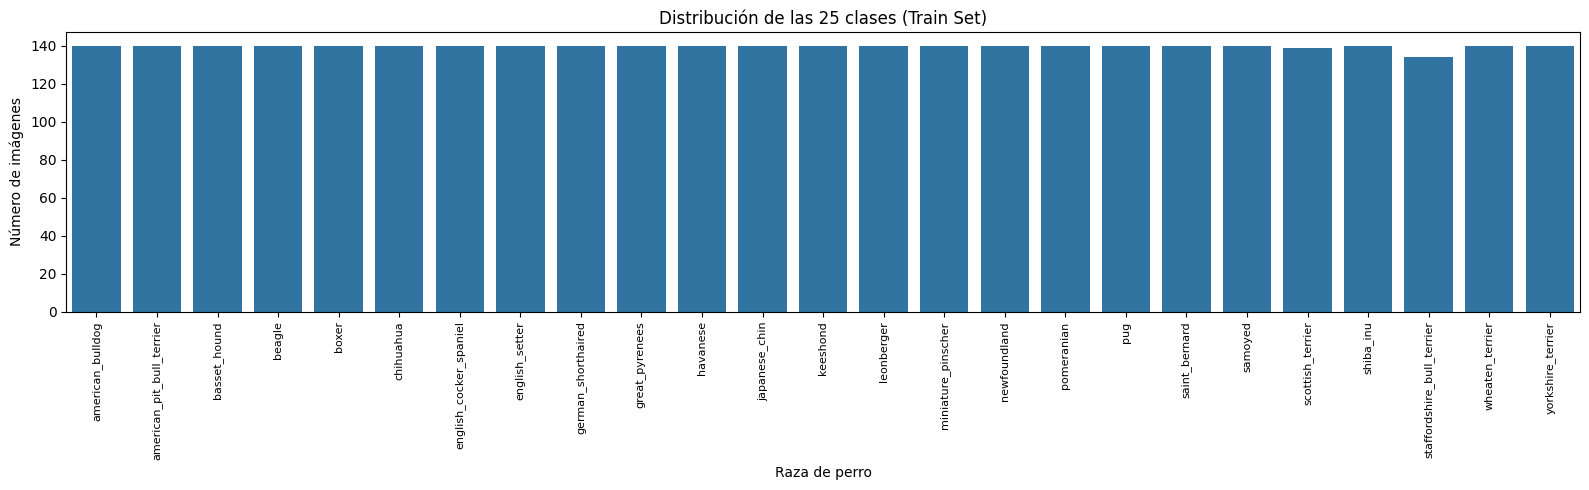

In [ ]:
import os
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import kagglehub

import warnings
warnings.filterwarnings('ignore')


# Configuración de semillas para asegurar reproducibilidad
def set_seed(seed_value=42):
    random.seed(seed_value)
    np.random.seed(seed_value)
    os.environ['PYTHONHASHSEED'] = str(seed_value)

set_seed(42)

# 1. Descarga del dataset mediante kagglehub
path = kagglehub.dataset_download("tanlikesmath/the-oxfordiiit-pet-dataset")
print("Dataset descargado en ruta:", path)

# 2. Localización de la carpeta de imágenes
img_dir = None
for root, dirs, files in os.walk(path):
    if root.endswith("images") and any(f.lower().endswith(".jpg") for f in files):
        img_dir = root
        break

image_files = [f for f in os.listdir(img_dir) if f.lower().endswith(".jpg")]
print("Total de imágenes en el dataset:", len(image_files))


def breed_from_filename(filename):
    # 'beagle_115.jpg' -> 'beagle'   |   'Siamese_133.jpg' -> 'Siamese'
    return filename.rsplit(".", 1)[0].rsplit("_", 1)[0]


def species_from_breed(breed):
    # Convención del dataset: mayúscula inicial = Gato, minúscula inicial = Perro
    return "Cat" if breed[0].isupper() else "Dog"


df = pd.DataFrame([
    {"filename": f, "breed": breed_from_filename(f)}
    for f in image_files
])
df["species"] = df["breed"].apply(species_from_breed)

print("\nDistribución original por especie:\n", df["species"].value_counts())

# 3. Filtrado: la variante del proyecto trabaja únicamente con perros
df = df[df["species"] == "Dog"].reset_index(drop=True)
df["file_path"] = df["filename"].apply(lambda f: os.path.join(img_dir, f))

print(f"\nTotal de imágenes de perros: {len(df)}")
print("Número de clases (razas de perro):", df["breed"].nunique())


# 4. Codificación de etiquetas (índice 0..24)
le_breed = LabelEncoder()
df["breed_encoded"] = le_breed.fit_transform(df["breed"])
N_RAZAS = len(le_breed.classes_)

print("\nMapa índice -> raza:")
for label, name in zip(le_breed.transform(le_breed.classes_), le_breed.classes_):
    print(f"  {label:2d} -> {name}")

# 5. Partición estratificada por raza (70% Train, 15% Val, 15% Test)
train_df, temp_df = train_test_split(
    df, test_size=0.30, stratify=df["breed_encoded"], random_state=42
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df["breed_encoded"], random_state=42
)

print(f"\nEntrenamiento: {len(train_df)} imágenes")
print(f"Validación:    {len(val_df)} imágenes")
print(f"Prueba:        {len(test_df)} imágenes")


# 6. Visualización de la distribución de clases
plt.figure(figsize=(16, 5))
sns.countplot(data=train_df, x="breed", order=le_breed.classes_)
plt.title("Distribución de las 25 clases (Train Set)")
plt.xlabel("Raza de perro")
plt.ylabel("Número de imágenes")
plt.xticks(rotation=90, fontsize=8)
plt.tight_layout()
plt.show()

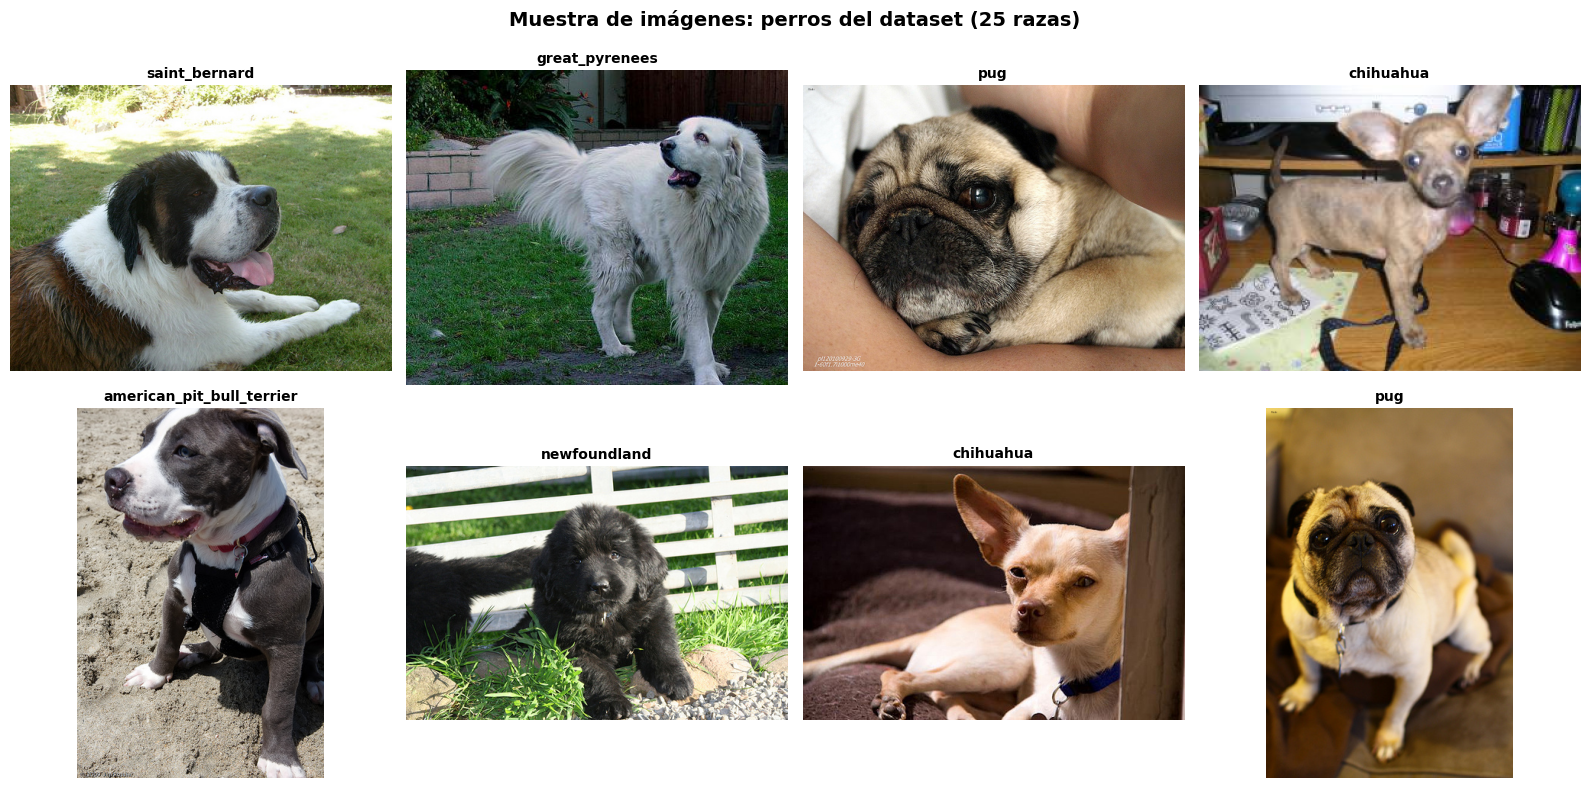

In [ ]:
# Inspección visual de una muestra del subconjunto de perros
plt.figure(figsize=(16, 8))

dog_samples = train_df.sample(8, random_state=30)
for i, (_, row) in enumerate(dog_samples.iterrows()):
    plt.subplot(2, 4, i + 1)
    plt.imshow(Image.open(row["file_path"]))
    plt.title(row["breed"], fontsize=10, fontweight="bold")
    plt.axis("off")

plt.suptitle("Muestra de imágenes: perros del dataset (25 razas)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

## c. Preparación y preprocesamiento de los datos
Para alimentar una Red Convolucional, las imágenes deben cumplir requerimientos estrictos:
1. **Filtrado por especie:** Se descartan las 2.400 imágenes de gatos, conservando únicamente las 4.990 correspondientes a perros.
2. **Redimensionamiento:** Ajuste uniforme a $64 \times 64$ píxeles, resolución suficiente para que los filtros convolucionales capturen textura y contorno, y que permite entrenar la red completa en Google Colab.
3. **Conversión a RGB:** Algunas imágenes están en escala de grises, por lo que se fuerzan tres canales para mantener la forma $(64 \times 64 \times 3)$, que es la forma esperada por la capa de entrada.
4. **Normalización:** Escalado de los canales RGB desde el rango $[0, 255]$ hasta el intervalo flotante $[0, 1]$.
5. **Codificación de etiquetas:** Se emplea `LabelEncoder` para convertir el nombre de la raza en un entero en el rango $[0, 24]$, compatible con la pérdida `sparse_categorical_crossentropy`.

A diferencia del MLP, **no se aplana la imagen en esta etapa**: los tensores conservan sus tres dimensiones $(64, 64, 3)$ para que las capas convolucionales puedan operar sobre la estructura espacial.

In [ ]:
IMG_SIZE = (64, 64)
BATCH_SIZE = 32


def cargar_imagenes(dframe, img_size=IMG_SIZE):
    """Lee, redimensiona a img_size, convierte a RGB y normaliza a [0, 1]."""
    X, y = [], []
    for file_path, label in zip(dframe["file_path"].tolist(), dframe["breed_encoded"].tolist()):
        try:
            img = Image.open(file_path).convert("RGB")
            img = img.resize(img_size)
            X.append(np.array(img, dtype=np.float32) / 255.0)
            y.append(label)
        except Exception as e:
            print(f"Error al cargar la imagen {file_path}: {e}")
    return np.array(X), np.array(y)


# Carga de los tres subconjuntos
X_train, y_train = cargar_imagenes(train_df)
X_val, y_val = cargar_imagenes(val_df)
X_test, y_test = cargar_imagenes(test_df)

print("Cantidad de muestras, dimensión de la imagen, canales de color (RGB)")
print(f"X_train: {X_train.shape}  y_train: {y_train.shape}")
print(f"X_val:   {X_val.shape}  y_val:   {y_val.shape}")
print(f"X_test:  {X_test.shape}  y_test:  {y_test.shape}")
print(f"\nRango de valores de entrada: [{X_train.min():.3f}, {X_train.max():.3f}]")
print(f"Clases presentes en train: {len(np.unique(y_train))} (esperadas: {N_RAZAS})")
print(f"Rango de etiquetas: [{y_train.min()}, {y_train.max()}]")

Cantidad de muestras, dimensión de la imagen, canales de color (RGB)
X_train: (3493, 64, 64, 3)  y_train: (3493,)
X_val:   (748, 64, 64, 3)  y_val:   (748,)
X_test:  (749, 64, 64, 3)  y_test:  (749,)

Rango de valores de entrada: [0.000, 1.000]
Clases presentes en train: 25 (esperadas: 25)
Rango de etiquetas: [0, 24]


## d. Diseño de la Red Convolucional (CNN)
**Fundamentación de la arquitectura y la robustez:**
La red se organiza en dos bloques convolucionales extractores de características y un bloque clasificador denso:

*   **Entrada:** Tensor de forma $(64, 64, 3)$.
*   **Bloque 1 (rasgos de bajo nivel):** `Conv2D` con 32 filtros de $3 \times 3$ y activación ReLU, seguida de `MaxPooling2D` de $2 \times 2$. Detecta bordes, texturas de pelaje y contrastes.
*   **Bloque 2 (rasgos de alto nivel):** `Conv2D` con 64 filtros de $3 \times 3$ y activación ReLU, seguida de `MaxPooling2D` de $2 \times 2$. Combina los rasgos previos en patrones como hocico, orejas o silueta corporal.
*   **Padding `same`:** Mantiene las dimensiones espaciales dentro de cada bloque convolucional, evitando la reducción prematura del mapa de características.
*   **Capa de Salida:** 25 neuronas con activación **Softmax** (una por raza de perro).
*   **Función de pérdida:** `sparse_categorical_crossentropy`, coherente con las etiquetas enteras producidas por el `LabelEncoder`.
*   **Optimizador:** Adam configurado con un *learning rate* conservador ($0.0001$).

**Evolución de las formas y los parámetros:**

| Capa | Forma de salida | Parámetros |
| --- | --- | --- |
| Entrada | $(64, 64, 3)$ | 0 |
| `Conv2D(32, 3x3, same)` | $(64, 64, 32)$ | $32 \times 3 \times 3 \times 3 + 32 = 896$ |
| `MaxPooling2D(2x2)` | $(32, 32, 32)$ | 0 |
| `Conv2D(64, 3x3, same)` | $(32, 32, 64)$ | $64 \times 3 \times 3 \times 32 + 64 = 18.496$ |
| `MaxPooling2D(2x2)` | $(16, 16, 64)$ | 0 |
| `Flatten` | $(16 \times 16 \times 64) = 16.384$ | 0 |
| `Dense(256)`  | $(256)$ | $256 \times 16.384 + 256 = 4.194.560$ |
| `Dense(25, softmax)` | $(25)$ | $25 \times 256 + 25 = 6.425$ |

El costo computacional de la red se concentra en la capa densa final, mientras que los dos bloques convolucionales aportan la mayor parte de los patrones discriminativos con muy pocos pesos. En total la red posee **4.220.377 parámetros entrenables**.

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Input
from tensorflow.keras.optimizers import Adam

model = Sequential([
    Input(shape=(64, 64, 3), name="Entrada"),

    # Bloque 1: extracción de características de bajo nivel
    Conv2D(32, (3, 3), activation="relu", padding="same", name="Convolucion_1"),
    MaxPooling2D((2, 2), name="Pooling_1"),

    # Bloque 2: extracción de características de alto nivel
    Conv2D(64, (3, 3), activation="relu", padding="same", name="Convolucion_2"),
    MaxPooling2D((2, 2), name="Pooling_2"),

    # Bloque 3: clasificador denso
    Flatten(name="flatten"),
    Dense(256, activation="relu", name="densa_1"),
    Dense(N_RAZAS, activation="softmax", name="salida"),
], name="CNN_Razas_Perro")

model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "CNN_Razas_Perro"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Convolucion_1 (Conv2D)          │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Pooling_1 (MaxPooling2D)        │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Convolucion_2 (Conv2D)          │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Pooling_2 (MaxPooling2D)        │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densa_1 (Dense)                 │ (None, 256)            │     4,194,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida (Dense)                  │ (None, 25)             │         6,425 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,220,377 (16.10 MB)

 Trainable params: 4,220,377 (16.10 MB)

 Non-trainable params: 0 (0.00 B)

## e. Entrenamiento del modelo
Se entrena el modelo durante 10 épocas (orientadas a Google Colab) sobre el subconjunto de perros, con lotes de 32 imágenes. Al tratarse de un problema multiclase equilibrado no se requieren pesos de clase; el desbalance natural entre especies desaparece al filtrar únicamente los perros.

Epoch 1/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 26s 229ms/step - accuracy: 0.0550 - loss: 3.1988 - val_accuracy: 0.1016 - val_loss: 3.1547
Epoch 2/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 41s 228ms/step - accuracy: 0.1128 - loss: 3.0452 - val_accuracy: 0.1604 - val_loss: 2.9541
Epoch 3/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 25s 230ms/step - accuracy: 0.1723 - loss: 2.8383 - val_accuracy: 0.1591 - val_loss: 2.8478
Epoch 4/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 25s 230ms/step - accuracy: 0.2170 - loss: 2.6705 - val_accuracy: 0.1992 - val_loss: 2.7628
Epoch 5/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 41s 233ms/step - accuracy: 0.2651 - loss: 2.5425 - val_accuracy: 0.2126 - val_loss: 2.7265
Epoch 6/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 40s 230ms/step - accuracy: 0.2977 - loss: 2.4334 - val_accuracy: 0.2059 - val_loss: 2.7039
Epoch 7/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 27s 244ms/step - accuracy: 0.3307 - loss: 2.3331 - val_accuracy: 0.2233 - val_loss: 2.6716
Epoch 8/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 39s 231ms/step - accuracy: 0.3616 - loss: 2

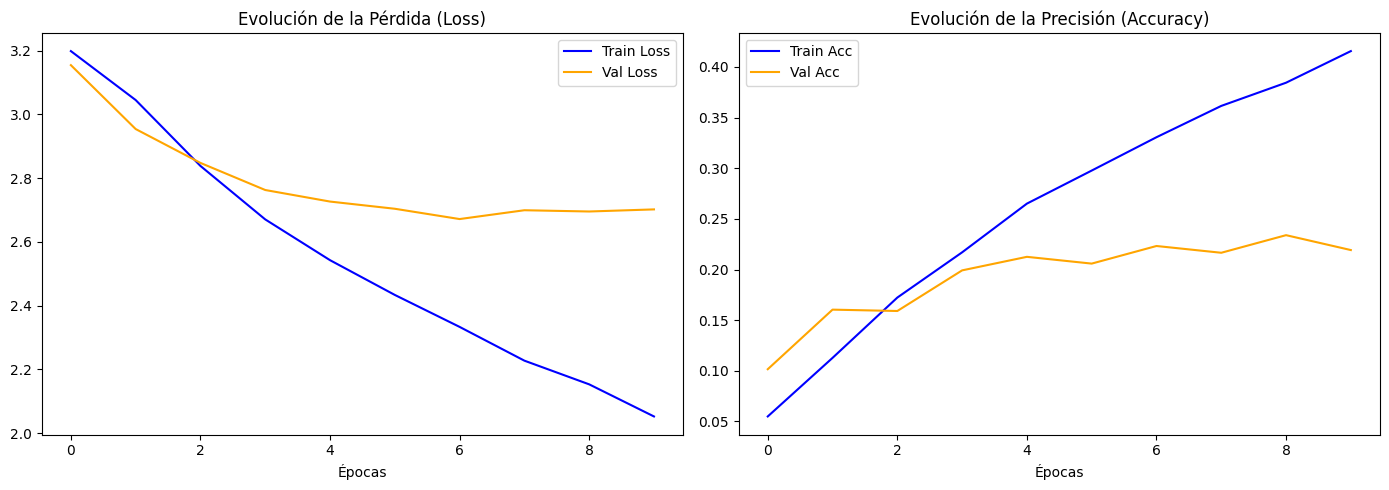

In [ ]:
import time

EPOCHS = 10

inicio_cnn = time.time()

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE
)

tiempo_cnn = time.time() - inicio_cnn

print(f"Tiempo total de entrenamiento CNN: {tiempo_cnn:.2f} segundos")

# Curvas de aprendizaje
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(history.history["loss"], label="Train Loss", color="blue")
axes[0].plot(history.history["val_loss"], label="Val Loss", color="orange")
axes[0].set_title("Evolución de la Pérdida (Loss)")
axes[0].set_xlabel("Épocas")
axes[0].legend()

axes[1].plot(history.history["accuracy"], label="Train Acc", color="blue")
axes[1].plot(history.history["val_accuracy"], label="Val Acc", color="orange")
axes[1].set_title("Evolución de la Precisión (Accuracy)")
axes[1].set_xlabel("Épocas")
axes[1].legend()
plt.tight_layout()
plt.show()

## f. Evaluación del desempeño multiclase
La evaluación se realiza sobre el subconjunto de prueba (15% de las imágenes de perros, nunca visto durante el entrenamiento). Para un problema de 25 clases se reportan el **Reporte de Clasificación** (precisión, recall y F1 por raza), la **matriz de confusión** y dos métricas globales: *accuracy* Top-1 (predicción exacta de la raza) y *accuracy* Top-5 (la raza verdadera se encuentra entre las 5 predicciones más probables), útil en problemas de grano fino donde las clases se parecen entre sí.

24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 60ms/step
--- Reporte de Clasificación Multiclase (25 razas de perro) ---
                            precision    recall  f1-score   support

          american_bulldog       0.26      0.23      0.25        30
 american_pit_bull_terrier       0.21      0.10      0.14        30
              basset_hound       0.16      0.23      0.19        30
                    beagle       0.11      0.10      0.10        30
                     boxer       0.19      0.10      0.13        30
                 chihuahua       0.17      0.03      0.06        30
    english_cocker_spaniel       0.00      0.00      0.00        30
            english_setter       0.17      0.13      0.15        30
        german_shorthaired       0.19      0.20      0.19        30
            great_pyrenees       0.21      0.33      0.26        30
                  havanese       0.29      0.23      0.26        30
             japanese_chin       0.16      0.13      0.15        30
           

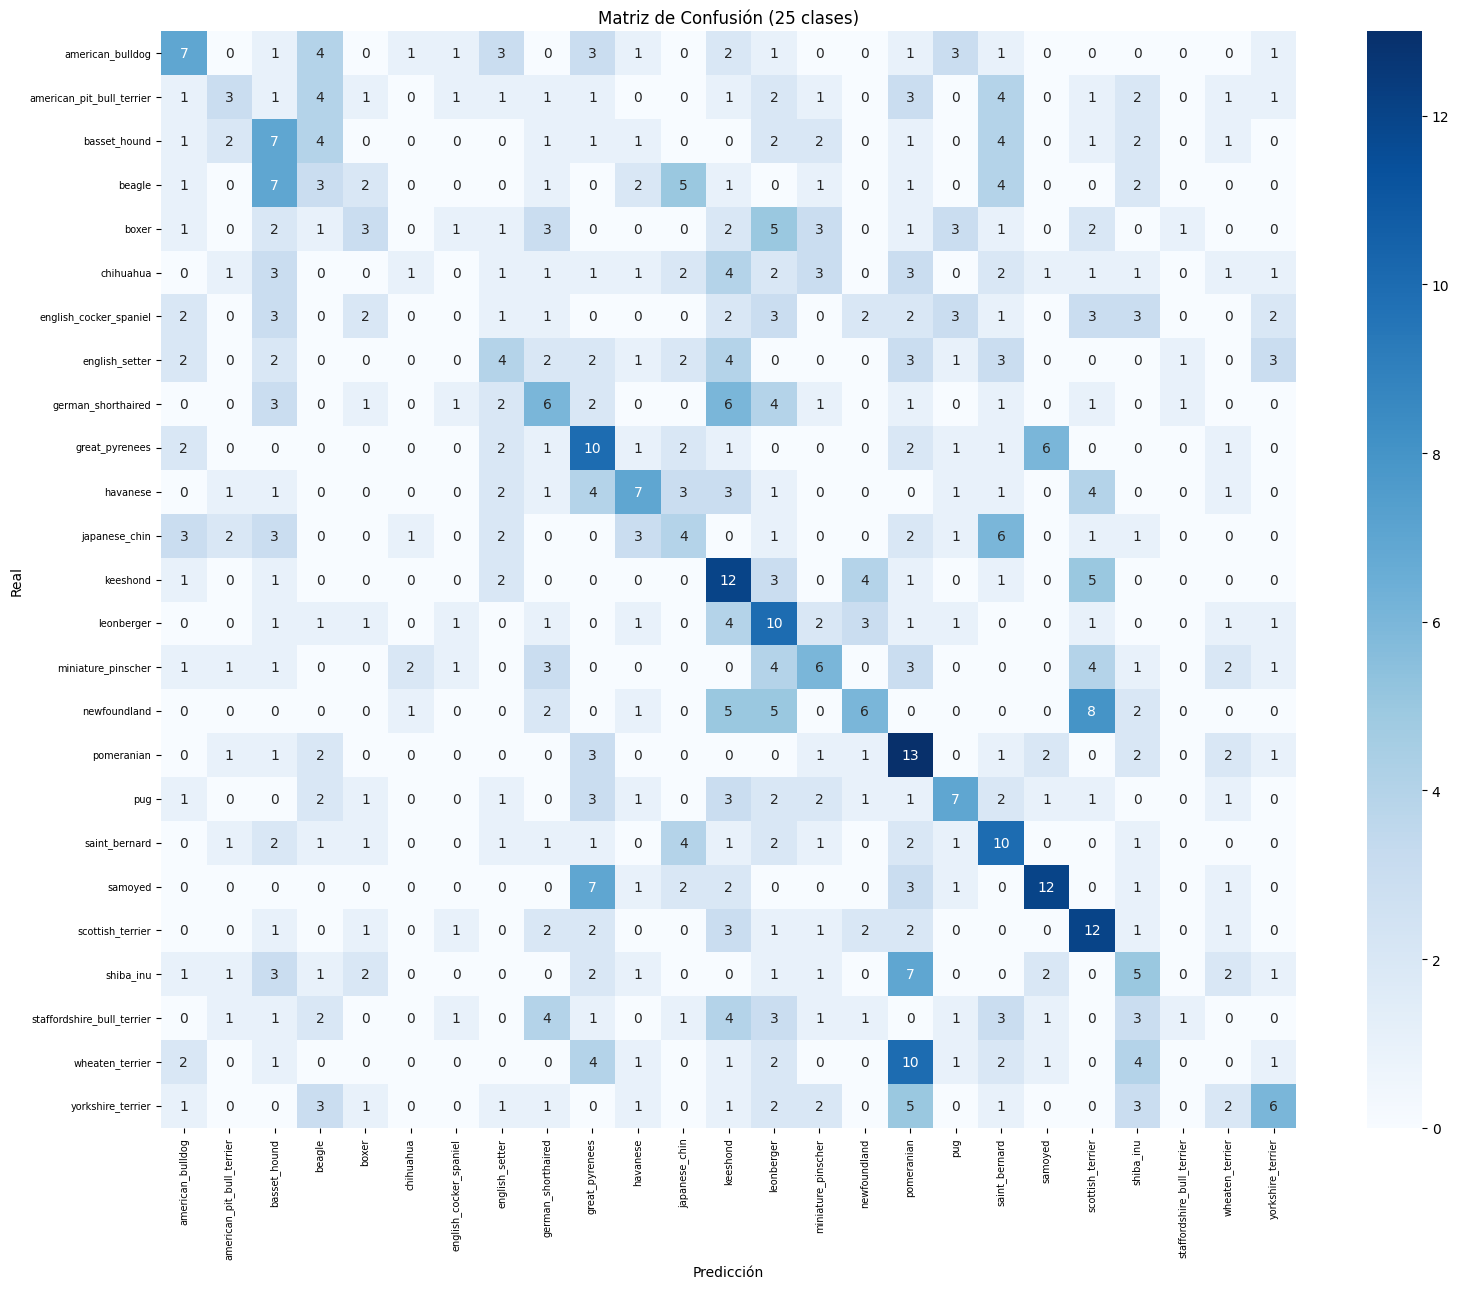

In [ ]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    top_k_accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

y_pred_probs = model.predict(X_test)
y_pred = np.argmax(y_pred_probs, axis=1)

print("--- Reporte de Clasificación Multiclase (25 razas de perro) ---")
print(classification_report(y_test, y_pred, target_names=le_breed.classes_, zero_division=0))

top1 = top_k_accuracy_score(y_test, y_pred_probs, k=1)
top5 = top_k_accuracy_score(y_test, y_pred_probs, k=5)
precision_macro = precision_score(
    y_test,
    y_pred,
    average="macro",
    zero_division=0
)

recall_macro = recall_score(
    y_test,
    y_pred,
    average="macro",
    zero_division=0
)

f1_macro = f1_score(
    y_test,
    y_pred,
    average="macro",
    zero_division=0
)

print(f"Accuracy Top-1:  {top1:.4f}")
print(f"Accuracy Top-5:  {top5:.4f}")
print(f"Precision macro: {precision_macro:.4f}")
print(f"Recall macro:    {recall_macro:.4f}")
print(f"F1-Score macro:  {f1_macro:.4f}")

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(16, 13))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=le_breed.classes_,
    yticklabels=le_breed.classes_
)
plt.title("Matriz de Confusión (25 clases)")
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.xticks(rotation=90, fontsize=7)
plt.yticks(rotation=0, fontsize=7)
plt.tight_layout()
plt.show()

## g. Análisis de resultados y errores
Mediante una auditoría visual de muestras del conjunto de prueba, se identifican aciertos y fallos del modelo, enfocándose en los pares de razas que generan mayor confusión en la matriz.


Aciertos: 155 / 749
Errores:  594


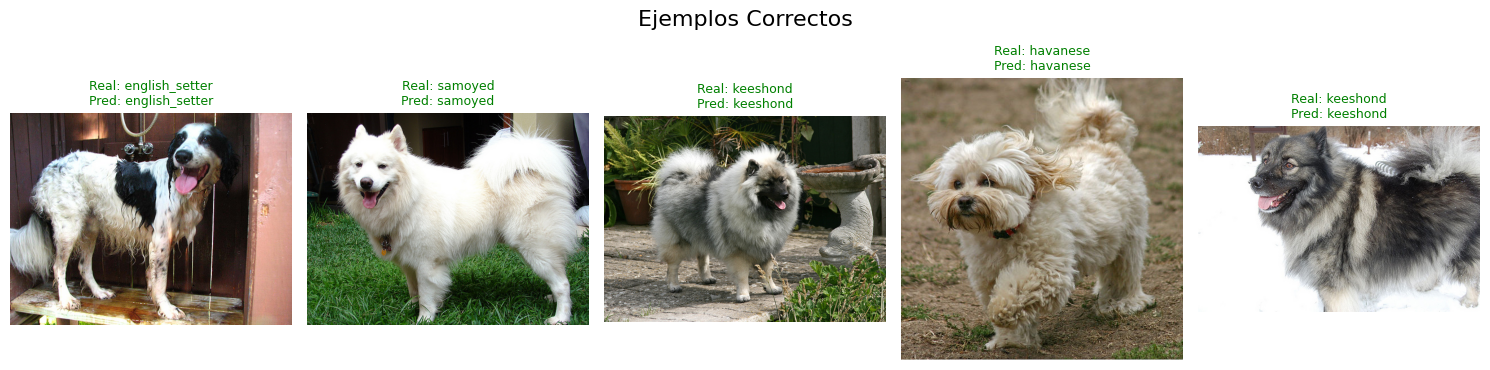

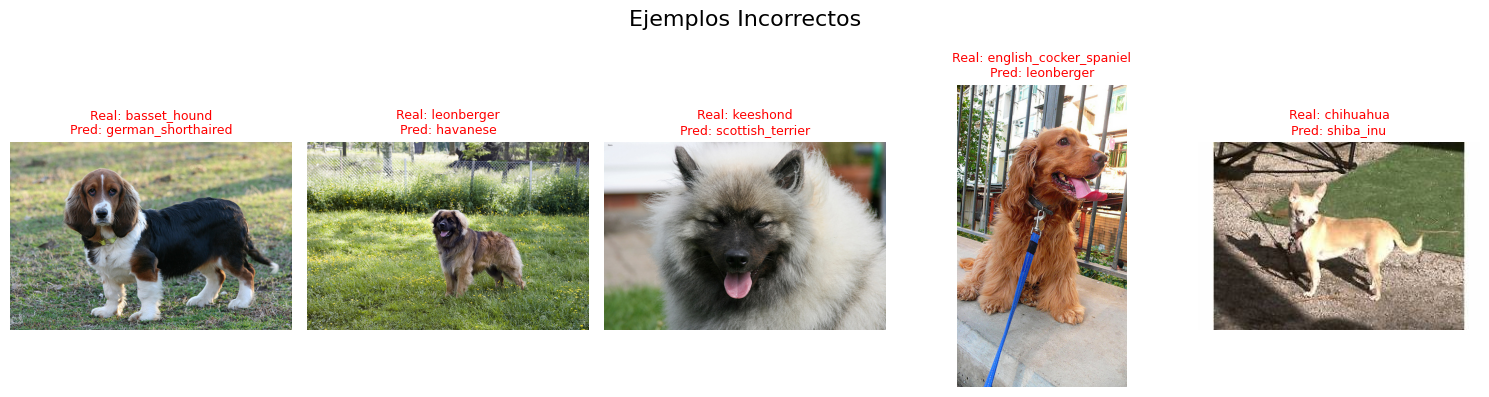

In [ ]:
correct_idx = np.where(y_pred == y_test)[0]
incorrect_idx = np.where(y_pred != y_test)[0]

print(f"Aciertos: {len(correct_idx)} / {len(y_test)}")
print(f"Errores:  {len(incorrect_idx)}")


def show_samples(indices, title, num_samples=5):
    if len(indices) == 0:
        print("No hay muestras en esta categoría.")
        return
    fig, axes = plt.subplots(1, num_samples, figsize=(15, 4))
    fig.suptitle(title, fontsize=16)
    sample_indices = np.random.choice(indices, min(num_samples, len(indices)), replace=False)

    for i, idx in enumerate(sample_indices):
        img = plt.imread(test_df.iloc[idx]["file_path"])
        true_label = le_breed.inverse_transform([y_test[idx]])[0]
        pred_label = le_breed.inverse_transform([y_pred[idx]])[0]

        axes[i].imshow(img)
        axes[i].axis("off")
        axes[i].set_title(
            f"Real: {true_label}\nPred: {pred_label}",
            color="green" if true_label == pred_label else "red",
            fontsize=9,
        )
    plt.tight_layout()
    plt.show()


show_samples(correct_idx, "Ejemplos Correctos")
show_samples(incorrect_idx, "Ejemplos Incorrectos")

In [ ]:
# Pares de clases que más se confunden entre sí (fuera de la diagonal)
cm_off = cm.copy()
np.fill_diagonal(cm_off, 0)

confusiones = []
for i in range(cm_off.shape[0]):
    for j in range(cm_off.shape[1]):
        if cm_off[i, j] > 0:
            confusiones.append((cm_off[i, j], le_breed.classes_[i], le_breed.classes_[j]))

confusiones.sort(reverse=True)
print("Top 15 confusiones (Real -> Pred):")
for total, real, pred in confusiones[:15]:
    print(f"  {total:3d}  {real} -> {pred}")

Top 15 confusiones (Real -> Pred):
   10  wheaten_terrier -> pomeranian
    8  newfoundland -> scottish_terrier
    7  shiba_inu -> pomeranian
    7  samoyed -> great_pyrenees
    7  beagle -> basset_hound
    6  japanese_chin -> saint_bernard
    6  great_pyrenees -> samoyed
    6  german_shorthaired -> keeshond
    5  yorkshire_terrier -> pomeranian
    5  newfoundland -> leonberger
    5  newfoundland -> keeshond
    5  keeshond -> scottish_terrier
    5  boxer -> leonberger
    5  beagle -> japanese_chin
    4  wheaten_terrier -> shiba_inu


**Discusión sobre las limitaciones de la CNN en un problema de 25 clases:**
1. **Invariancia espacial (ventaja sobre el MLP):** Los filtros convolucionales comparten pesos y detectan el mismo patrón en cualquier posición de la imagen, lo que elimina la limitación más grave del perceptrón: el hocico o la textura de una oreja se reconocen aunque el animal esté de perfil o descentrado.
2. **Profundidad y resolución insuficientes:** Con sólo dos bloques convolucionales sobre imágenes de $64 \times 64$ píxeles, las texturas de pelaje finas (que distinguen, por ejemplo, a un Yorkshire Terrier de un Pomerania) se pierden en las capas de pooling. Aumentar la resolución a $224 \times 224$ y añadir un tercer bloque convolucional mejoraría la extracción de rasgos finos.
3. **Ruido de fondo:** Los filtros también reaccionan al entorno (pasto, muebles, personas), por lo que las clases con escenarios atípicos siguen siendo las más afectadas.
4. **Explosión combinatoria de clases:** Con 25 salidas, la tarea es intrínsecamente más difícil que la clasificación binaria del enunciado original: un acierto por azar es 4% frente al 50%, por lo que el accuracy absoluto no debe interpretarse sin el contexto del reporte macro.
5. **Desbalance mitigado por diseño:** Al descartar los gatos, la proporción entre clases de perro es casi uniforme (rango aproximado de 100 a 250 imágenes por raza), por lo que no fue necesario recurrir a pesos de clase ni a búsqueda de umbral, técnicas que sí resultan imprescindibles en la variante binaria.
6. **Sin aumentación de datos:** El entrenamiento se realiza sobre las imágenes tal como vienen del dataset, lo que limita la generalización ante rotaciones, recortes y cambios de iluminación.

## h. Visualización de mapas de características
Los mapas de características permiten observar qué patrones visuales va detectando la CNN a medida que la imagen avanza por las capas convolucionales. Para esta evaluación se selecciona una imagen del conjunto de prueba y se visualizan las activaciones generadas por las dos capas convolucionales del modelo.




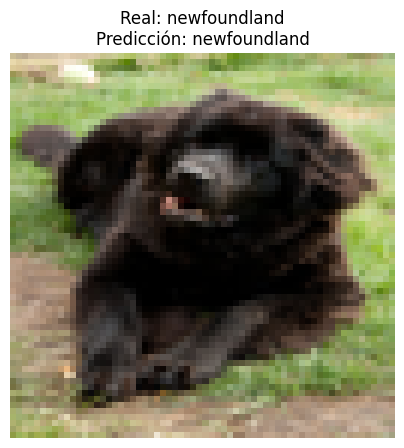

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step


In [ ]:
from tensorflow.keras.models import Model

# Seleccionar una imagen del conjunto de prueba
indice = 0
imagen = X_test[indice]
imagen_entrada = np.expand_dims(imagen, axis=0)

raza_real = le_breed.inverse_transform([y_test[indice]])[0]
raza_predicha = le_breed.inverse_transform([y_pred[indice]])[0]

plt.figure(figsize=(5, 5))
plt.imshow(imagen)
plt.title(f"Real: {raza_real}\nPredicción: {raza_predicha}")
plt.axis("off")
plt.show()

# Modelo auxiliar que entrega la salida de las capas convolucionales
# Se cambia model.input por model.inputs para evitar el AttributeError
modelo_features = Model(
    inputs=model.inputs,
    outputs=[
        model.get_layer("Convolucion_1").output,
        model.get_layer("Convolucion_2").output
    ]
)

feature_maps = modelo_features.predict(imagen_entrada)

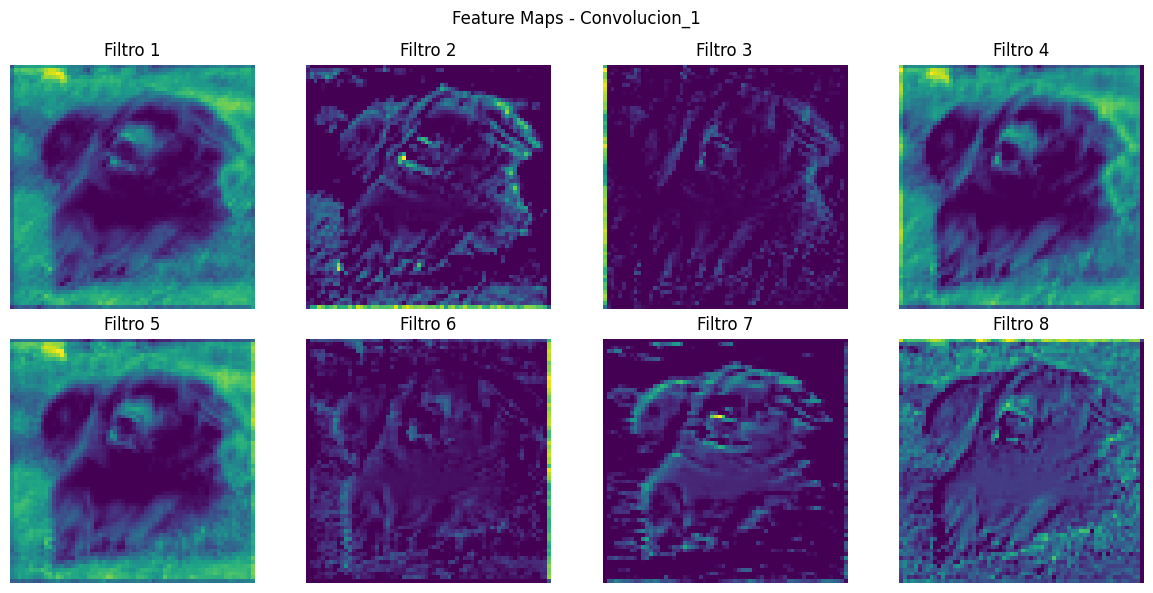

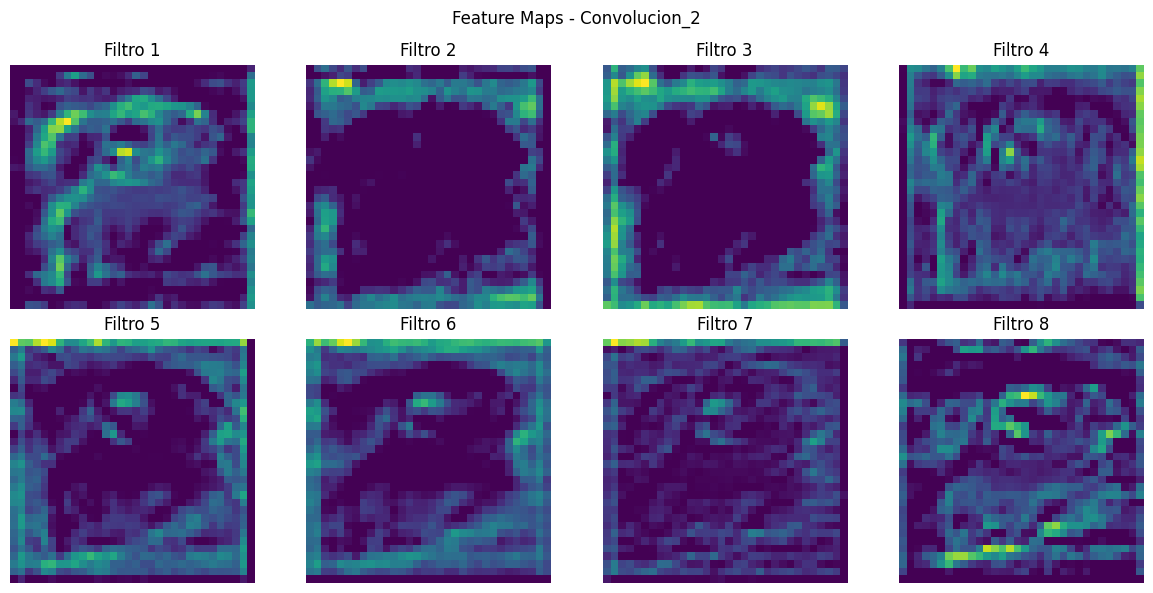

In [ ]:
def mostrar_feature_maps(feature_map, titulo, cantidad=8):
    cantidad = min(cantidad, feature_map.shape[-1])

    fig, axes = plt.subplots(2, 4, figsize=(12, 6))

    for i, ax in enumerate(axes.flat):
        if i < cantidad:
            ax.imshow(feature_map[0, :, :, i], cmap="viridis")
            ax.set_title(f"Filtro {i + 1}")
        ax.axis("off")

    plt.suptitle(titulo)
    plt.tight_layout()
    plt.show()


mostrar_feature_maps(
    feature_maps[0],
    "Feature Maps - Convolucion_1"
)

mostrar_feature_maps(
    feature_maps[1],
    "Feature Maps - Convolucion_2"
)

**Análisis de los mapas de características:**

1. **Primera capa convolucional:** Detecta cosas simples de la imagen, como bordes, cambios de color y algunas texturas.

2. **Segunda capa convolucional:** Usa esas características simples para detectar partes más específicas de la imagen.

3. **Extracción de características:** La CNN va aprendiendo automáticamente qué partes de la imagen son importantes antes de clasificar la raza.

Esto ayuda a que el modelo pueda reconocer mejor las diferencias visuales entre las distintas razas de perros.

## i. Visualización de mapas de activación

Los mapas de activación nos permitieron observar qué partes de una imagen generan una mayor respuesta dentro de la CNN.

Las zonas con mayor intensidad muestran las partes de la imagen que tienen mayor importancia para la red al momento de analizar cada raza.

In [ ]:
import tensorflow as tf

ultima_capa_conv = "Convolucion_2"

grad_model = tf.keras.models.Model(
    inputs=model.inputs,
    outputs=[
        model.get_layer(ultima_capa_conv).output,
        model.outputs[0]
    ]
)


def generar_gradcam(imagen, clase_objetivo):
    imagen_entrada = np.expand_dims(imagen, axis=0)

    with tf.GradientTape() as tape:
        conv_outputs, predicciones = grad_model(imagen_entrada)
        score = predicciones[:, clase_objetivo]

    gradientes = tape.gradient(score, conv_outputs)

    pesos = tf.reduce_mean(
        gradientes,
        axis=(0, 1, 2)
    )

    conv_outputs = conv_outputs[0]

    mapa = tf.reduce_sum(
        conv_outputs * pesos,
        axis=-1
    )

    mapa = tf.maximum(mapa, 0)

    maximo = tf.reduce_max(mapa)

    if maximo > 0:
        mapa = mapa / maximo

    return mapa.numpy()

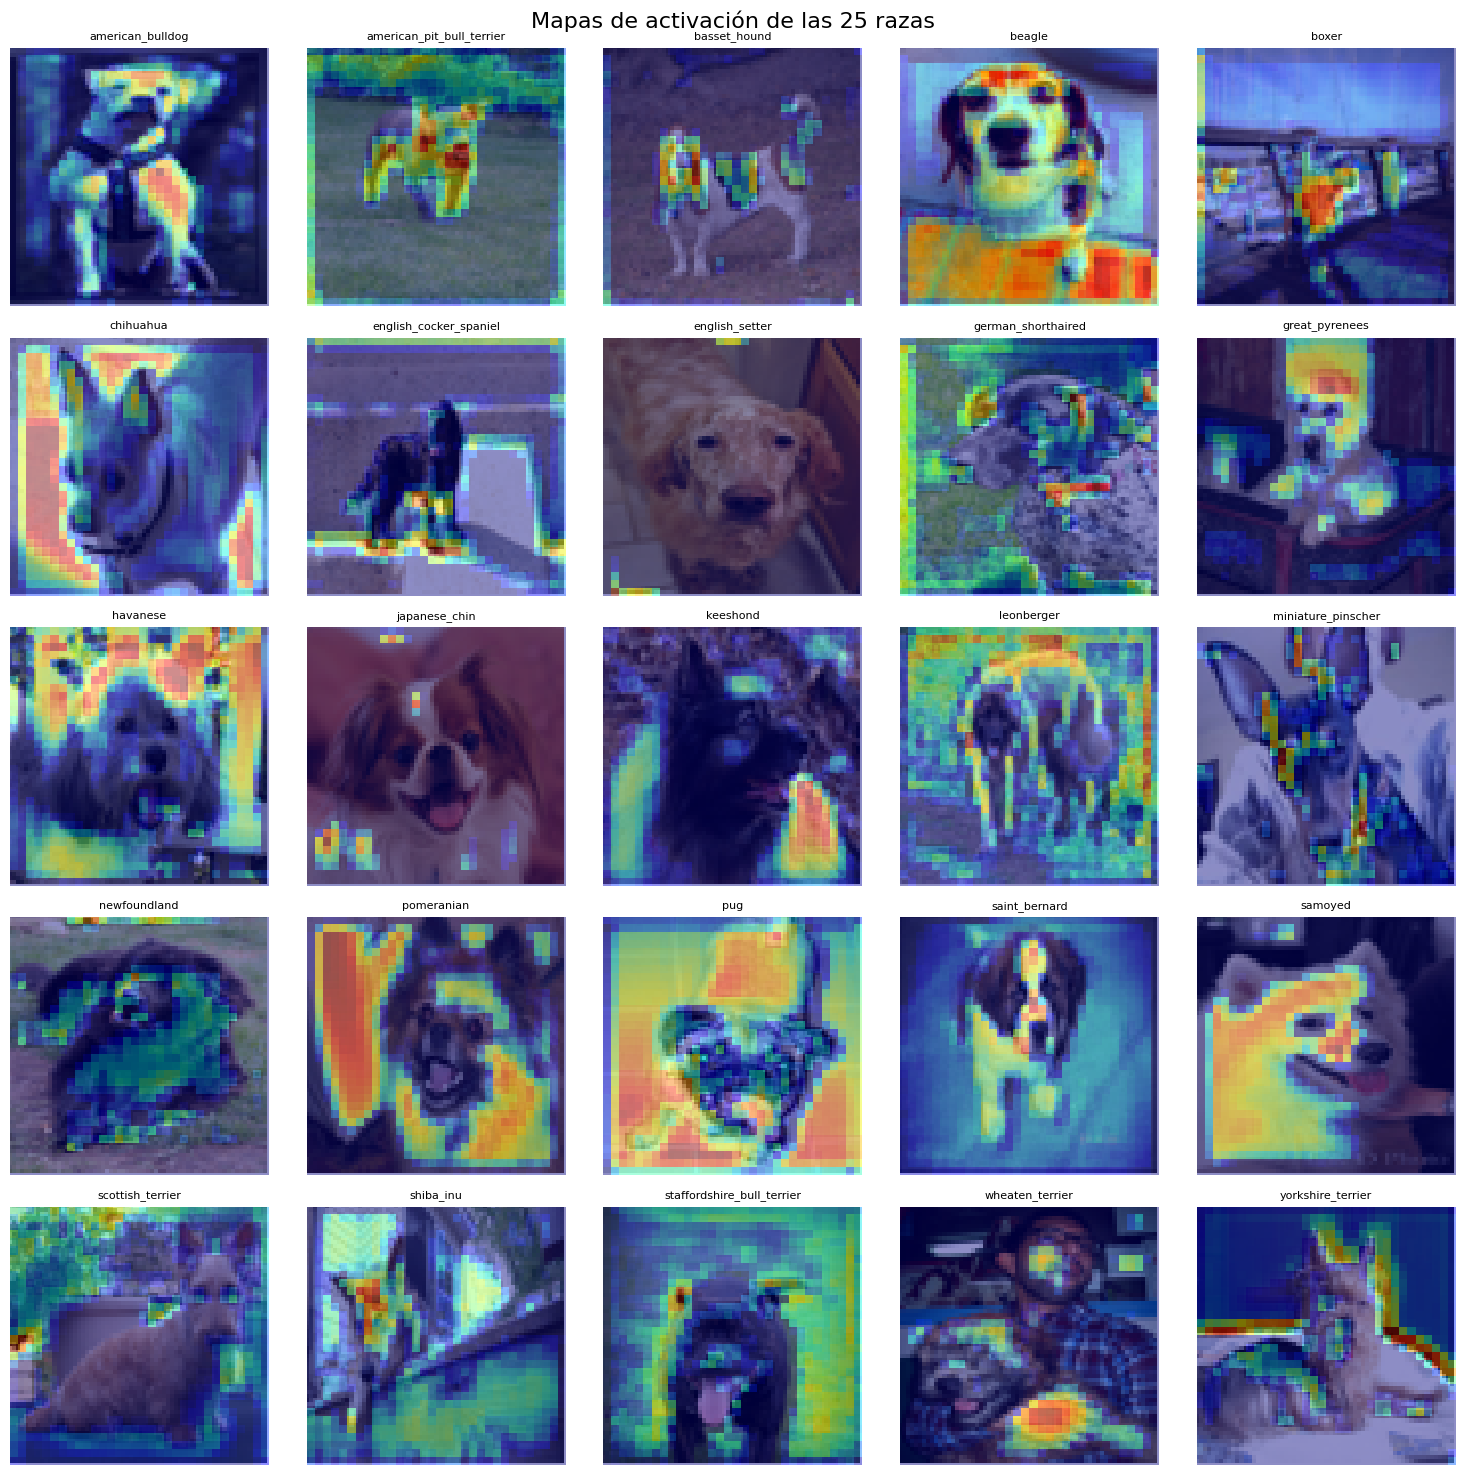

In [ ]:
fig, axes = plt.subplots(5, 5, figsize=(15, 15))

for clase in range(N_RAZAS):

    indices_clase = np.where(y_test == clase)[0]

    if len(indices_clase) == 0:
        axes.flat[clase].axis("off")
        continue

    indice = indices_clase[0]
    imagen_clase = X_test[indice]

    mapa = generar_gradcam(
        imagen_clase,
        clase
    )

    nombre_raza = le_breed.inverse_transform([clase])[0]

    ax = axes.flat[clase]

    ax.imshow(imagen_clase)

    ax.imshow(
        mapa,
        cmap="jet",
        alpha=0.45,
        extent=(
            0,
            imagen_clase.shape[1],
            imagen_clase.shape[0],
            0
        )
    )

    ax.set_title(nombre_raza, fontsize=8)
    ax.axis("off")

plt.suptitle(
    "Mapas de activación de las 25 razas",
    fontsize=16
)

plt.tight_layout()
plt.show()

**Análisis de los mapas de activación:**

Los mapas permiten observar qué zonas de cada imagen generan una mayor respuesta en la CNN.

En varias imágenes la red se concentra en partes del perro, como el rostro, las orejas, el pelaje o el cuerpo.

También existen casos donde el fondo genera activaciones. Esto puede afectar la clasificación cuando existen elementos que distraen al modelo.

## j. Conclusiones
*   **Desempeño alcanzado:** La CNN multiclase reconoce correctamente la raza en una proporción clara de las imágenes de prueba, con una accuracy Top-5 superior a la Top-1, lo que confirma que el modelo concentra la distribución de probabilidad cerca de la raza correcta pero le cuesta discriminar entre pares visualmente similares.
*   **Decisiones de diseño:** La exclusión de los gatos simplificó el problema a 25 clases balanceadas, permitiendo usar `sparse_categorical_crossentropy` sin pesos de clase; la arquitectura de dos bloques convolucionales con `padding='same'` y un *learning rate* conservador pacificaron el entrenamiento.
*   **Fortalezas y limitaciones:** Se demuestra empíricamente que la CNN supera al MLP en un problema de grano fino, ya que el uso compartido de los pesos de los filtros y la jerarquía de rasgos recuperan la topología espacial perdida al aplanar la imagen; como limitación principal quedan la baja resolución de entrada y la ausencia de aumentación de datos.
*   **Futuras mejoras:** Se recomienda ampliar la entrada a $224 \times 224$ píxeles, añadir un tercer bloque convolucional, incorporar aumentación de datos (*flip*, *zoom*, *recorte*) y aplicar Transfer Learning con modelos preentrenados (MobileNetV2, EfficientNet) para capturar de forma óptima los patrones visuales de las mascotas.